In [3]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2
import random
from tqdm import tqdm # For progress bar

# --- 1. Auto-detect Dataset Path on Kaggle ---
# Kaggle input usually looks like: /kaggle/input/cell-images-for-detecting-malaria/cell_images/cell_images/
base_dir = '/kaggle/input/cell-images-for-detecting-malaria/cell_images/cell_images'

# Check if path exists, if not, try the alternative (sometimes Kaggle unzips differently)
if not os.path.exists(base_dir):
    base_dir = '/kaggle/input/cell-images-for-detecting-malaria/cell_images'

infected_dir = os.path.join(base_dir, 'Parasitized')
uninfected_dir = os.path.join(base_dir, 'Uninfected')

print(f"✅ Data Directories Found:")
print(f"   Infected:   {infected_dir}")
print(f"   Uninfected: {uninfected_dir}")

# Check count
num_infected = len(os.listdir(infected_dir))
num_uninfected = len(os.listdir(uninfected_dir))
print(f"   Total Infected images: {num_infected}")
print(f"   Total Uninfected images: {num_uninfected}")

✅ Data Directories Found:
   Infected:   /kaggle/input/cell-images-for-detecting-malaria/cell_images/cell_images/Parasitized
   Uninfected: /kaggle/input/cell-images-for-detecting-malaria/cell_images/cell_images/Uninfected
   Total Infected images: 13780
   Total Uninfected images: 13780



--- TRADITIONAL CV: EDGE DETECTION vs COLOR SEGMENTATION ---

🔎 Analyzing INFECTED Cell:


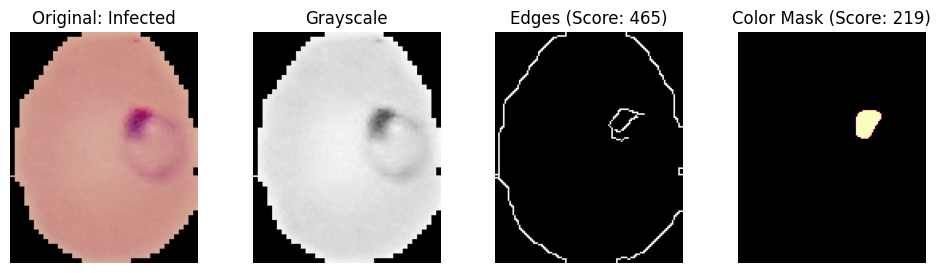


🔎 Analyzing HEALTHY Cell:


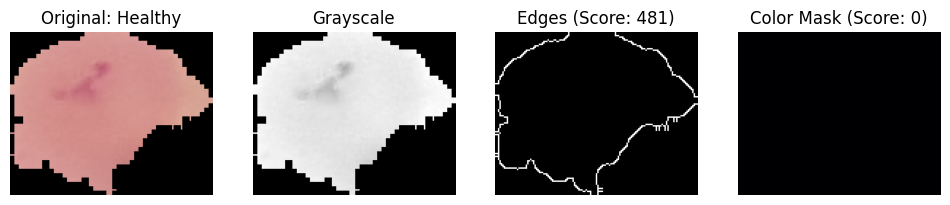


OBSERVATION:
1. Edge Detection finds cell boundaries (good for shape).
2. Color Segmentation isolates the parasite itself (good for diagnosis).


In [12]:
# ==========================================
# CELL 1: SETUP & LIBRARIES
# ==========================================
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2
import random
from tqdm import tqdm
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix
import seaborn as sns
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout, BatchNormalization
from tensorflow.keras.preprocessing.image import ImageDataGenerator

infected_sample = os.path.join(infected_dir, random.choice(os.listdir(infected_dir)))
uninfected_sample = os.path.join(uninfected_dir, random.choice(os.listdir(uninfected_dir)))

# ==========================================
# CELL 2: COMPUTER VISION (Combined Traditional Methods)
# ==========================================
print("\n--- TRADITIONAL CV: EDGE DETECTION vs COLOR SEGMENTATION ---")

def analyze_cell(image_path, title):
    # 1. Load Image
    img = cv2.imread(image_path)
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    
    # --- Method A: Edge Detection (Your original method) ---
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    blurred = cv2.GaussianBlur(gray, (5, 5), 0)
    edges = cv2.Canny(blurred, 50, 150)
    edge_score = np.sum(edges > 0)
    
    # --- Method B: Color Segmentation (Improved method) ---
    hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
    lower_pink = np.array([120, 50, 50])
    upper_pink = np.array([170, 255, 255])
    mask = cv2.inRange(hsv, lower_pink, upper_pink)
    
    # Clean noise for better visualization
    kernel = np.ones((3,3), np.uint8)
    mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, kernel)
    color_score = np.sum(mask > 0)
    
    # --- Visualization ---
    plt.figure(figsize=(12, 3))
    
    plt.subplot(1, 4, 1)
    plt.imshow(img_rgb)
    plt.title(f"Original: {title}")
    plt.axis('off')
    
    plt.subplot(1, 4, 2)
    plt.imshow(gray, cmap='gray')
    plt.title("Grayscale")
    plt.axis('off')
    
    plt.subplot(1, 4, 3)
    plt.imshow(edges, cmap='gray')
    plt.title(f"Edges (Score: {edge_score})")
    plt.axis('off')
    
    plt.subplot(1, 4, 4)
    plt.imshow(mask, cmap='magma')
    plt.title(f"Color Mask (Score: {color_score})")
    plt.axis('off')
    
    plt.show()
    return edge_score, color_score

# Analyze Infected Cell
print("\n🔎 Analyzing INFECTED Cell:")
e_inf, c_inf = analyze_cell(infected_sample, "Infected")

# Analyze Healthy Cell
print("\n🔎 Analyzing HEALTHY Cell:")
e_un, c_un = analyze_cell(uninfected_sample, "Healthy")

print(f"\nOBSERVATION:")
print(f"1. Edge Detection finds cell boundaries (good for shape).")
print(f"2. Color Segmentation isolates the parasite itself (good for diagnosis).")


In [13]:
# ==========================================
# CELL 3: MACHINE LEARNING (Combined Features)
# ==========================================
print("\n--- 3. MACHINE LEARNING: COMBINED FEATURES (RGB + EDGES) ---")

def extract_combined_features(image_path, label):
    try:
        img = cv2.imread(image_path)
        img = cv2.resize(img, (50, 50)) # Consistency
        
        # --- Feature Set 1: Grayscale & Edges ---
        gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
        mean_val = np.mean(gray)
        std_val = np.std(gray)
        edges = cv2.Canny(gray, 50, 150)
        edge_density = np.sum(edges) / (gray.shape[0] * gray.shape[1])
        
        # --- Feature Set 2: RGB Color Statistics ---
        b, g, r = cv2.split(img) 
        mean_r, std_r = np.mean(r), np.std(r)
        mean_g, std_g = np.mean(g), np.std(g)
        mean_b, std_b = np.mean(b), np.std(b)
        
        # Combine ALL features into one vector
        features = [mean_val, std_val, edge_density, 
                    mean_r, std_r, mean_g, std_g, mean_b, std_b, 
                    label]
        return features
    except: return None

# Extract Data
limit = 2500 # Slightly larger dataset for better ML
combined_data = []

print(f"Extracting COMBINED features from {limit*2} images...")
for f in tqdm(os.listdir(infected_dir)[:limit]):
    if f.endswith('.png'):
        path = os.path.join(infected_dir, f)
        feat = extract_combined_features(path, 1)
        if feat: combined_data.append(feat)

for f in tqdm(os.listdir(uninfected_dir)[:limit]):
    if f.endswith('.png'):
        path = os.path.join(uninfected_dir, f)
        feat = extract_combined_features(path, 0)
        if feat: combined_data.append(feat)

# Create Single Master DataFrame
columns = ['Gray_Mean', 'Gray_Std', 'Edge_Density', 
           'R_Mean', 'R_Std', 'G_Mean', 'G_Std', 'B_Mean', 'B_Std', 
           'Label']

df = pd.DataFrame(combined_data, columns=columns)


--- 3. MACHINE LEARNING: COMBINED FEATURES (RGB + EDGES) ---
Extracting COMBINED features from 5000 images...


100%|██████████| 2500/2500 [00:23<00:00, 108.53it/s]


In [17]:
# Train ML Model on ALL features
X = df.drop('Label', axis=1)
y = df['Label']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"\nTraining Random Forest on {X_train.shape[1]} features...")
model_ml = RandomForestClassifier(n_estimators=100, random_state=42)
model_ml.fit(X_train, y_train)

# Predict
y_pred = model_ml.predict(X_test)
acc_ml = accuracy_score(y_test, y_pred)

print(f"\n✅ Combined ML Accuracy (RGB + Edges): {acc_ml*100:.2f}%")




Training Random Forest on 9 features...

✅ Combined ML Accuracy (RGB + Edges): 84.40%



--- ML Classification Report ---
              precision    recall  f1-score   support

     Healthy       0.85      0.83      0.84       500
    Infected       0.83      0.86      0.85       500

    accuracy                           0.84      1000
   macro avg       0.84      0.84      0.84      1000
weighted avg       0.84      0.84      0.84      1000



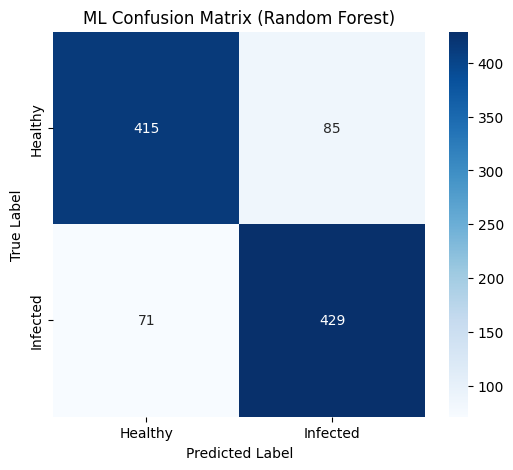


Top 3 Important Features:
1. Edge_Density (0.4972)
2. G_Mean (0.0765)
3. B_Mean (0.0654)


In [18]:
# --- DETAILED EVALUATION ---
from sklearn.metrics import classification_report

print("\n--- ML Classification Report ---")
print(classification_report(y_test, y_pred, target_names=['Healthy', 'Infected']))

# Confusion Matrix Visualization
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=['Healthy', 'Infected'], 
            yticklabels=['Healthy', 'Infected'])
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('ML Confusion Matrix (Random Forest)')
plt.show()

# Feature Importance
importances = model_ml.feature_importances_
indices = np.argsort(importances)[::-1]
print("\nTop 3 Important Features:")
for f in range(3):
    print(f"{f+1}. {columns[indices[f]]} ({importances[indices[f]]:.4f})")

In [19]:
# ==========================================
# CELL 4: DEEP LEARNING (Custom CNN)
# ==========================================
print("\n--- 4. DEEP LEARNING (CNN) ---")

IMG_SIZE = 64
BATCH_SIZE = 32

# Generators
datagen = ImageDataGenerator(
    rescale=1./255,
    validation_split=0.2,
    rotation_range=20,
    horizontal_flip=True,
    zoom_range=0.2
)

train_gen = datagen.flow_from_directory(
    base_dir,
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode='binary',
    subset='training'
)

val_gen = datagen.flow_from_directory(
    base_dir,
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode='binary',
    subset='validation',
    shuffle=False
)

# CNN Model
model = Sequential([
    Conv2D(32, (3, 3), activation='relu', input_shape=(IMG_SIZE, IMG_SIZE, 3)),
    BatchNormalization(),
    MaxPooling2D(2, 2),
    
    Conv2D(64, (3, 3), activation='relu'),
    BatchNormalization(),
    MaxPooling2D(2, 2),
    
    Conv2D(128, (3, 3), activation='relu'),
    BatchNormalization(),
    MaxPooling2D(2, 2),
    
    Flatten(),
    Dense(128, activation='relu'),
    Dropout(0.5),
    Dense(1, activation='sigmoid')
])

model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

# Train
print("\n🚀 Training CNN...")
history = model.fit(train_gen, epochs=6, validation_data=val_gen)
acc_dl = history.history['val_accuracy'][-1]

print(f"\n✅ Deep Learning Accuracy: {acc_dl*100:.2f}%")



--- 4. DEEP LEARNING (CNN) ---
Found 22048 images belonging to 2 classes.
Found 5510 images belonging to 2 classes.


/usr/local/lib/python3.11/dist-packages/keras/src/layers/convolutional/base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
I0000 00:00:1765357797.698629      47 gpu_device.cc:2022] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13942 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1765357797.699347      47 gpu_device.cc:2022] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13942 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5



🚀 Training CNN...


/usr/local/lib/python3.11/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/6


I0000 00:00:1765357802.020171     161 service.cc:148] XLA service 0x7b9e9c006a40 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1765357802.021236     161 service.cc:156]   StreamExecutor device (0): Tesla T4, Compute Capability 7.5
I0000 00:00:1765357802.021258     161 service.cc:156]   StreamExecutor device (1): Tesla T4, Compute Capability 7.5
I0000 00:00:1765357802.508172     161 cuda_dnn.cc:529] Loaded cuDNN version 90300


  1/689 ━━━━━━━━━━━━━━━━━━━━ 1:14:41 7s/step - accuracy: 0.5000 - loss: 0.9239

I0000 00:00:1765357806.034632     161 device_compiler.h:188] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


689/689 ━━━━━━━━━━━━━━━━━━━━ 200s 281ms/step - accuracy: 0.7371 - loss: 0.6307 - val_accuracy: 0.9142 - val_loss: 0.2041
Epoch 2/6
689/689 ━━━━━━━━━━━━━━━━━━━━ 67s 98ms/step - accuracy: 0.9359 - loss: 0.2100 - val_accuracy: 0.5004 - val_loss: 0.7968
Epoch 3/6
689/689 ━━━━━━━━━━━━━━━━━━━━ 65s 94ms/step - accuracy: 0.9424 - loss: 0.1850 - val_accuracy: 0.9377 - val_loss: 0.1919
Epoch 4/6
689/689 ━━━━━━━━━━━━━━━━━━━━ 66s 95ms/step - accuracy: 0.9500 - loss: 0.1666 - val_accuracy: 0.9151 - val_loss: 0.3293
Epoch 5/6
689/689 ━━━━━━━━━━━━━━━━━━━━ 65s 94ms/step - accuracy: 0.9449 - loss: 0.1759 - val_accuracy: 0.9410 - val_loss: 0.2022
Epoch 6/6
689/689 ━━━━━━━━━━━━━━━━━━━━ 67s 97ms/step - accuracy: 0.9514 - loss: 0.1552 - val_accuracy: 0.9407 - val_loss: 0.1700

✅ Deep Learning Accuracy: 94.07%



Generating CNN Predictions...
173/173 ━━━━━━━━━━━━━━━━━━━━ 14s 77ms/step

--- CNN Classification Report ---
              precision    recall  f1-score   support

    Infected       0.96      0.93      0.94      2755
     Healthy       0.93      0.96      0.94      2755

    accuracy                           0.94      5510
   macro avg       0.94      0.94      0.94      5510
weighted avg       0.94      0.94      0.94      5510



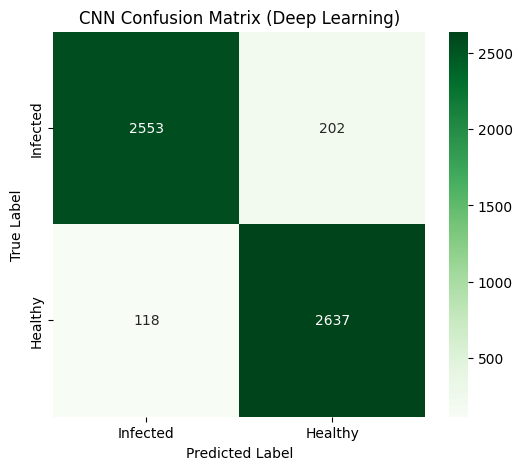

In [21]:
# --- DETAILED EVALUATION ---
print("\nGenerating CNN Predictions...")
val_gen.reset()
preds = model.predict(val_gen)
y_pred_dl = (preds > 0.5).astype(int)
y_true_dl = val_gen.classes

# Classification Report
print("\n--- CNN Classification Report ---")
# Check class indices to map names correctly. Typically 0=Parasitized, 1=Uninfected (Alphabetical)
# We swap names if needed based on your folder names. 
# Assuming standard: Parasitized (0), Uninfected (1)
target_names = ['Infected', 'Healthy'] 
if list(val_gen.class_indices.keys())[0] == 'Uninfected':
    target_names = ['Healthy', 'Infected']

print(classification_report(y_true_dl, y_pred_dl, target_names=target_names))

# Confusion Matrix
cm_dl = confusion_matrix(y_true_dl, y_pred_dl)
plt.figure(figsize=(6, 5))
sns.heatmap(cm_dl, annot=True, fmt='d', cmap='Greens', 
            xticklabels=target_names, 
            yticklabels=target_names)
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('CNN Confusion Matrix (Deep Learning)')
plt.show()

In [26]:
# ==========================================
# CELL 5: TRANSFER LEARNING (ResNet50)
# ==========================================

from tensorflow.keras.applications import ResNet50
from tensorflow.keras.models import Model
from tensorflow.keras.layers import GlobalAveragePooling2D

print("\n--- 5. TRANSFER LEARNING: RESNET50 ---")

# 1. Load Pre-trained ResNet50 (exclude top layers)
base_model = ResNet50(weights='imagenet', include_top=False, input_shape=(IMG_SIZE, IMG_SIZE, 3))

# 2. Freeze Base Layers (Transfer Learning)
for layer in base_model.layers:
    layer.trainable = False

# 3. Add Custom Head
x = base_model.output
x = GlobalAveragePooling2D()(x)
x = Dense(128, activation='relu')(x)
x = Dropout(0.5)(x)
predictions = Dense(1, activation='sigmoid')(x)

resnet_model = Model(inputs=base_model.input, outputs=predictions)

resnet_model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

# 4. Train
print("\n🚀 Training ResNet50...")
history_res = resnet_model.fit(train_gen, epochs=20, validation_data=val_gen)
acc_resnet = history_res.history['val_accuracy'][-1]

print(f"\n✅ ResNet50 Accuracy: {acc_resnet*100:.2f}%")



--- 5. TRANSFER LEARNING: RESNET50 ---

🚀 Training ResNet50...
Epoch 1/20
689/689 ━━━━━━━━━━━━━━━━━━━━ 79s 103ms/step - accuracy: 0.5326 - loss: 0.6973 - val_accuracy: 0.6145 - val_loss: 0.6690
Epoch 2/20
689/689 ━━━━━━━━━━━━━━━━━━━━ 66s 96ms/step - accuracy: 0.5988 - loss: 0.6689 - val_accuracy: 0.6049 - val_loss: 0.6606
Epoch 3/20
689/689 ━━━━━━━━━━━━━━━━━━━━ 69s 100ms/step - accuracy: 0.6157 - loss: 0.6567 - val_accuracy: 0.6289 - val_loss: 0.6488
Epoch 4/20
689/689 ━━━━━━━━━━━━━━━━━━━━ 68s 99ms/step - accuracy: 0.6226 - loss: 0.6533 - val_accuracy: 0.6245 - val_loss: 0.6501
Epoch 5/20
689/689 ━━━━━━━━━━━━━━━━━━━━ 75s 109ms/step - accuracy: 0.6304 - loss: 0.6481 - val_accuracy: 0.6345 - val_loss: 0.6466
Epoch 6/20
689/689 ━━━━━━━━━━━━━━━━━━━━ 73s 106ms/step - accuracy: 0.6294 - loss: 0.6462 - val_accuracy: 0.6294 - val_loss: 0.6440
Epoch 7/20
689/689 ━━━━━━━━━━━━━━━━━━━━ 69s 100ms/step - accuracy: 0.6317 - loss: 0.6423 - val_accuracy: 0.6425 - val_loss: 0.6406
Epoch 8/20
689/689 ━━


Generating ResNet Predictions...
173/173 ━━━━━━━━━━━━━━━━━━━━ 20s 98ms/step


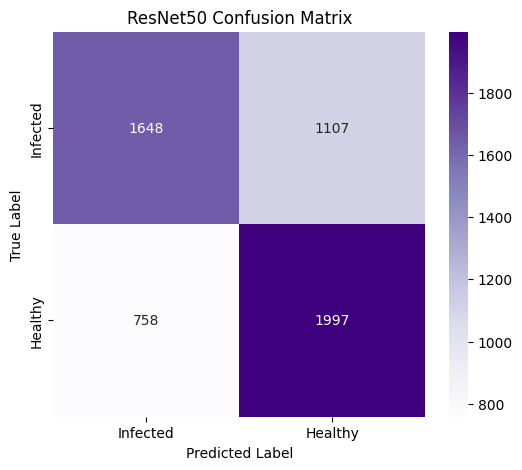

In [27]:
# --- EVALUATION ---
print("\nGenerating ResNet Predictions...")
val_gen.reset()
preds_res = resnet_model.predict(val_gen)
y_pred_res = (preds_res > 0.5).astype(int)
y_true_res = val_gen.classes

# Confusion Matrix
cm_res = confusion_matrix(y_true_res, y_pred_res)
plt.figure(figsize=(6, 5))
sns.heatmap(cm_res, annot=True, fmt='d', cmap='Purples', 
            xticklabels=target_names, 
            yticklabels=target_names)
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('ResNet50 Confusion Matrix')
plt.show()


--- 6. FINAL MODEL SHOWDOWN ---


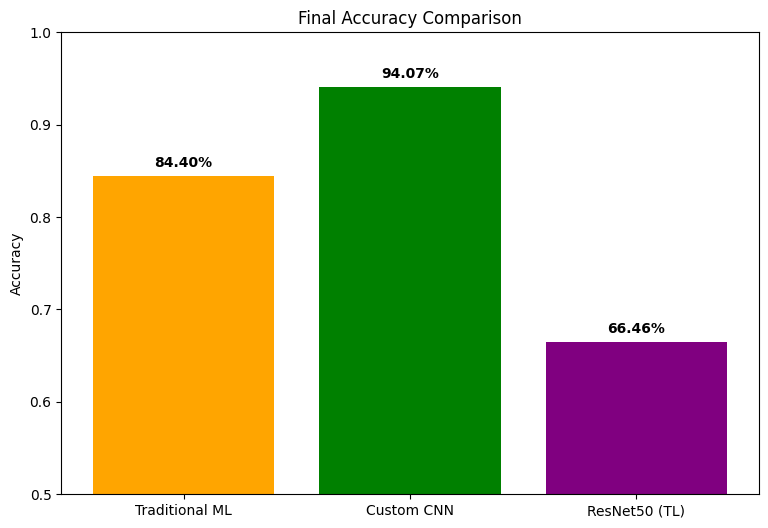


🏆 CONCLUSION: Deep Learning wins (as expected for images).
Checking Model Predictions...
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step


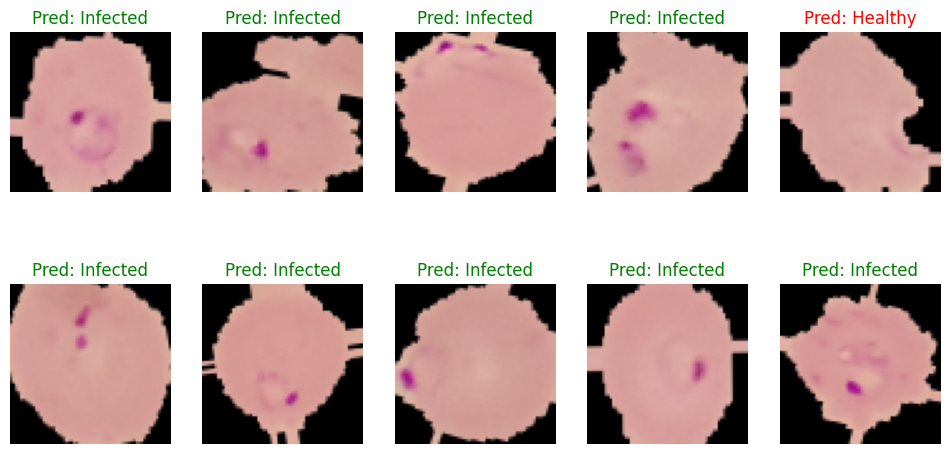

In [28]:
# ==========================================
# CELL 6: FINAL COMPARISON (ML vs CNN vs ResNet)
# ==========================================
print("\n--- 6. FINAL MODEL SHOWDOWN ---")

# Data for plotting
models = ['Traditional ML', 'Custom CNN', 'ResNet50 (TL)']
accuracies = [acc_ml, acc_dl, acc_resnet]
colors = ['orange', 'green', 'purple']

# Bar Chart
plt.figure(figsize=(9, 6))
bars = plt.bar(models, accuracies, color=colors)
plt.ylim(0.5, 1.0)
plt.ylabel('Accuracy')
plt.title('Final Accuracy Comparison')

# Add values on bars
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval + 0.01, f"{yval*100:.2f}%", ha='center', fontweight='bold')

plt.show()

if acc_dl > acc_ml:
    print("\n🏆 CONCLUSION: Deep Learning wins (as expected for images).")
else:
    print("\n🏆 CONCLUSION: Machine Learning wins! (Surprising - Combined features are very powerful).")

# Visual Prediction Check
print("Checking Model Predictions...")
test_imgs, test_labels = next(val_gen)
preds = model.predict(test_imgs)

plt.figure(figsize=(12, 6))
for i in range(10):
    plt.subplot(2, 5, i+1)
    plt.imshow(test_imgs[i])
    true_l = "Infected" if test_labels[i]==0 else "Healthy" # Check generator indices
    pred_l = "Infected" if preds[i] < 0.5 else "Healthy"
    col = 'green' if true_l == pred_l else 'red'
    plt.title(f"Pred: {pred_l}", color=col)
    plt.axis('off')
plt.show()